# Proyecto 2 Técnicas de Aprendizaje de Máquina: Siniestros Víales

## Importación de librerias

In [1]:
%pip install scikit-learn
%pip install kagglehub
%pip install pandas 
%pip install numpy 
%pip install matplotlib 
%pip install seaborn 
%pip install plotly


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


... (4 outputs left out)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn 

c:\Users\carlo\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Lectura del Archivo

In [4]:
df = pd.read_csv("historico_siniestros_bogota_d.c_-.csv", encoding="utf-8")

## Análisis de dimensionalidad

In [5]:
df.head()  # Muestra las primeras filas del DataFrame

,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0


### Tipo de datos

In [6]:
print(df.info())  # Información general del DataFrame

<class 'pandas.DataFrame'>
RangeIndex: 199146 entries, 0 to 199145
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   X                     199146 non-null  float64
 1   Y                     199146 non-null  float64
 2   OBJECTID              199146 non-null  int64  
 3   FORMULARIO            199146 non-null  str    
 4   CODIGO_ACCIDENTE      199146 non-null  int64  
 5   FECHA_OCURRENCIA_ACC  199146 non-null  str    
 6   ANO_OCURRENCIA_ACC    199146 non-null  int64  
 7   DIRECCION             199146 non-null  str    
 8   GRAVEDAD              199146 non-null  str    
 9   CLASE_ACC             199146 non-null  str    
 10  LOCALIDAD             199100 non-null  str    
 11  FECHA_HORA_ACC        199146 non-null  str    
 12  LATITUD               199146 non-null  float64
 13  LONGITUD              199146 non-null  float64
 14  CIV                   197445 non-null  float64
 15  PK_CALZADA 

In [7]:
# Nulos por columna
df.isnull().sum()

X                           0
Y                           0
OBJECTID                    0
FORMULARIO                  0
CODIGO_ACCIDENTE            0
FECHA_OCURRENCIA_ACC        0
ANO_OCURRENCIA_ACC          0
DIRECCION                   0
GRAVEDAD                    0
CLASE_ACC                   0
LOCALIDAD                  46
FECHA_HORA_ACC              0
LATITUD                     0
LONGITUD                    0
CIV                      1701
PK_CALZADA              37974
dtype: int64

In [8]:
# =========================================================
# 1. DIMENSIONALIDAD Y CARDINALIDAD
# =========================================================
card = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "pct_unicos": (df.nunique() / len(df) * 100).round(2)
}).sort_values("valores_unicos", ascending=False)
print(card)

# Columnas con un valor distinto por fila = identificadores
ids = card[card["pct_unicos"] > 99].index.tolist()
print("\nPosibles identificadores:", ids)

# ¿X/Y son lo mismo que LONGITUD/LATITUD?
print("\nDiferencia máx X vs LONGITUD:", (df["X"] - df["LONGITUD"]).abs().max())
print("Diferencia máx Y vs LATITUD:", (df["Y"] - df["LATITUD"]).abs().max())

                         tipo  valores_unicos  pct_unicos
FORMULARIO                str          199146      100.00
OBJECTID                int64          199146      100.00
CODIGO_ACCIDENTE        int64          199146      100.00
FECHA_HORA_ACC            str          162457       81.58
Y                     float64          110417       55.45
X                     float64          109453       54.96
LATITUD               float64          108427       54.45
LONGITUD              float64          107698       54.08
DIRECCION                 str          100085       50.26
CIV                   float64           38419       19.29
PK_CALZADA            float64           37953       19.06
FECHA_OCURRENCIA_ACC      str            2445        1.23
LOCALIDAD                 str              20        0.01
ANO_OCURRENCIA_ACC      int64               7        0.00
CLASE_ACC                 str               7        0.00
GRAVEDAD                  str               3        0.00

Posibles iden

In [10]:
# Posibles filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 0


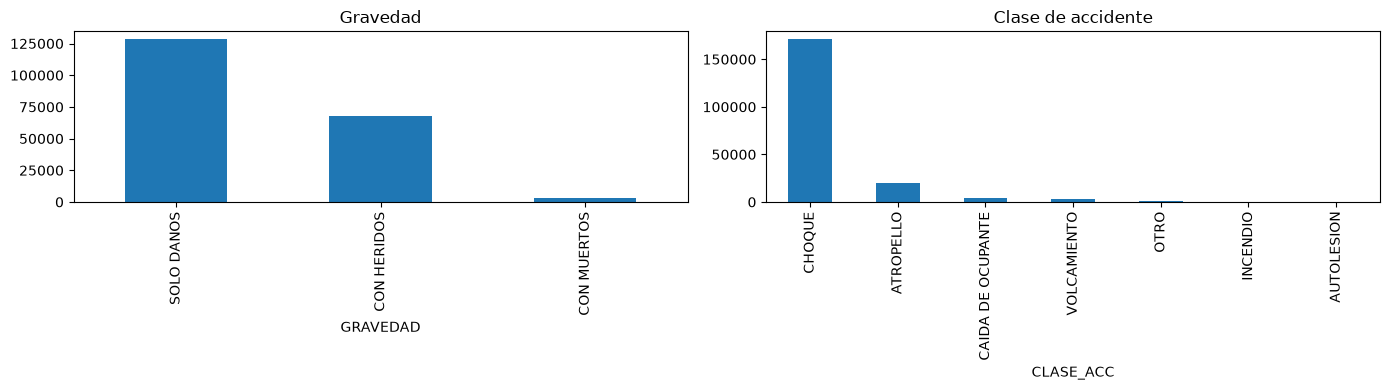

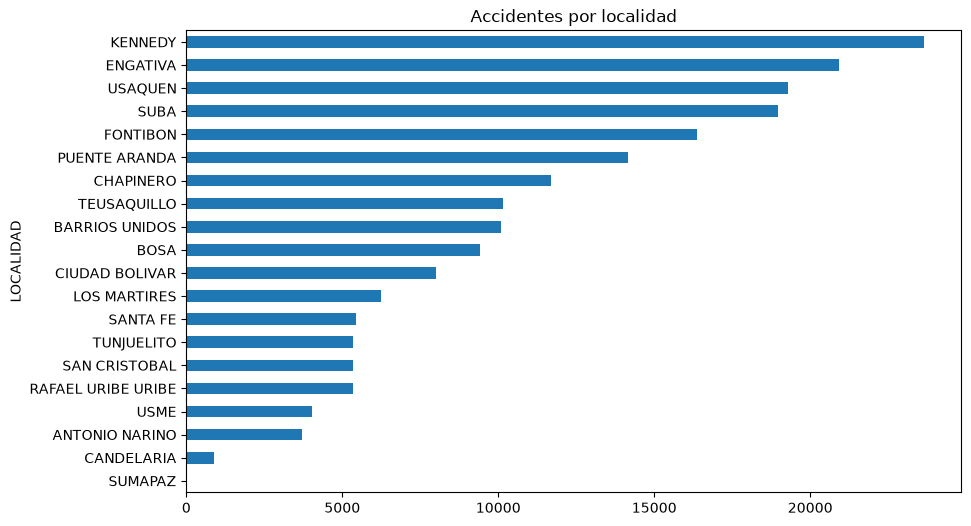

GRAVEDAD,CON HERIDOS,CON MUERTOS,SOLO DANOS
LOCALIDAD,,,
ANTONIO NARINO,43.9,2.2,53.9
BARRIOS UNIDOS,27.4,1.0,71.6
BOSA,46.8,2.1,51.1
CANDELARIA,33.7,1.7,64.6
CHAPINERO,23.1,0.8,76.1
CIUDAD BOLIVAR,46.2,3.1,50.7
ENGATIVA,30.9,1.4,67.7
FONTIBON,25.3,1.4,73.3
KENNEDY,40.6,1.9,57.5


In [11]:
# =========================================================
# 3. VARIABLES CATEGÓRICAS (BASE COMPLETA)
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["GRAVEDAD"].value_counts().plot(kind="bar", ax=axes[0], title="Gravedad")
df["CLASE_ACC"].value_counts().plot(kind="bar", ax=axes[1], title="Clase de accidente")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 6))
df["LOCALIDAD"].value_counts().plot(kind="barh", title="Accidentes por localidad")
plt.gca().invert_yaxis(); plt.show()

# Proporción de gravedad dentro de cada localidad
pd.crosstab(df["LOCALIDAD"], df["GRAVEDAD"], normalize="index").round(3) * 100

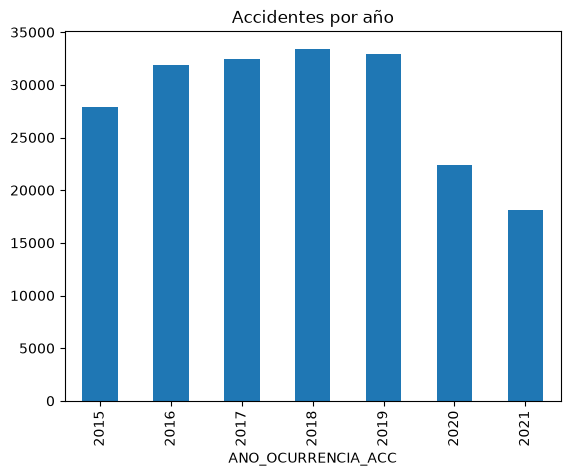

In [12]:
# =========================================================
# 4. VARIABLES TEMPORALES DERIVADAS
# =========================================================
df["FECHA_HORA"] = pd.to_datetime(df["FECHA_HORA_ACC"].str[:19], format="%Y/%m/%d %H:%M:%S")
df["HORA"] = df["FECHA_HORA"].dt.hour
df["DIA_SEMANA"] = df["FECHA_HORA"].dt.dayofweek          # 0 = lunes
df["MES"] = df["FECHA_HORA"].dt.month
df["FIN_SEMANA"] = df["DIA_SEMANA"].isin([5, 6]).astype(int)

def franja(h):
    if h < 6:   return "Madrugada"
    if h < 12:  return "Mañana"
    if h < 18:  return "Tarde"
    return "Noche"
df["FRANJA"] = df["HORA"].apply(franja)

# Accidentes por año (ojo con 2020-2021 por la pandemia)
df["ANO_OCURRENCIA_ACC"].value_counts().sort_index().plot(kind="bar", title="Accidentes por año")
plt.show()

Accidentes con muertos: 3239 (1.63% del total)


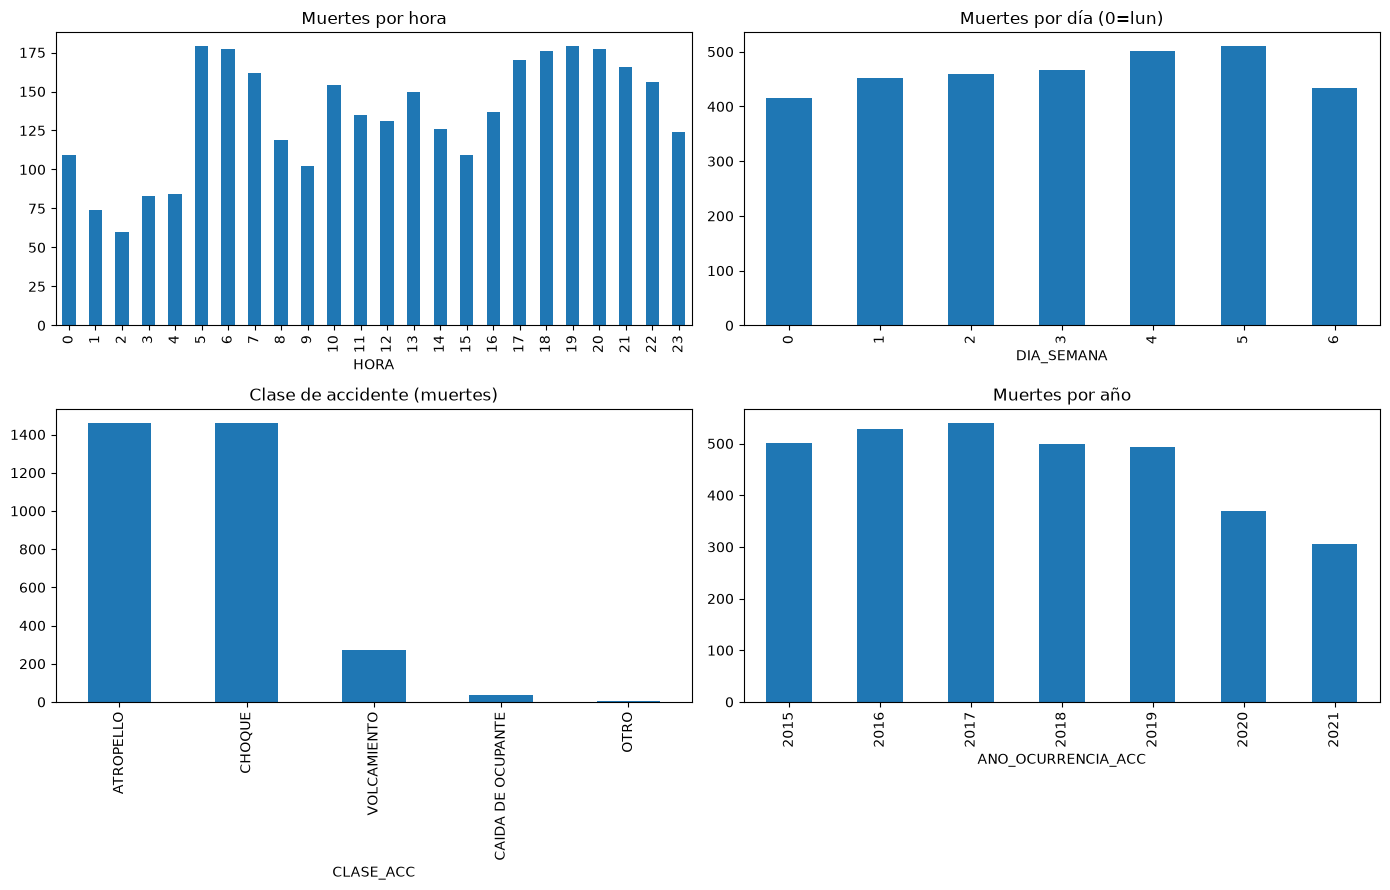

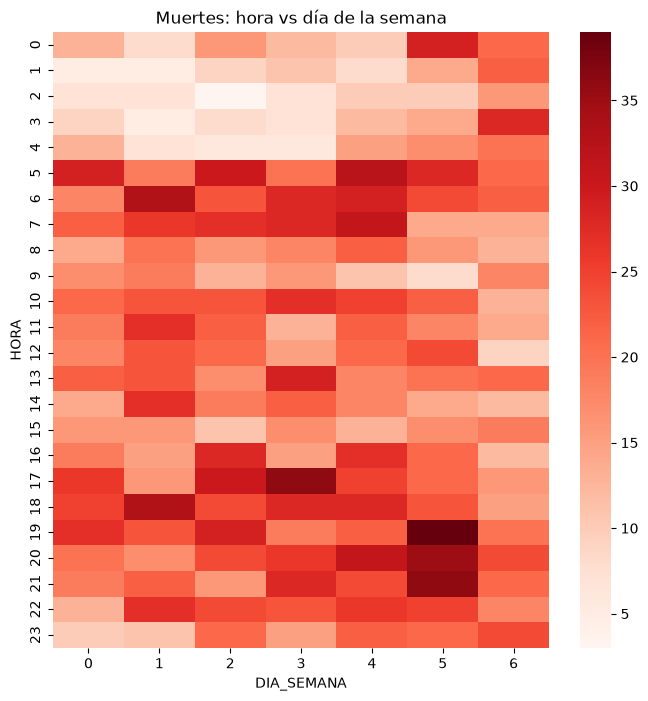

In [13]:
# =========================================================
# 5. FILTRO: ACCIDENTES CON MUERTOS (foco del proyecto)
# =========================================================
dm = df[df["GRAVEDAD"] == "CON MUERTOS"].copy()
print("Accidentes con muertos:", len(dm), f"({len(dm)/len(df)*100:.2f}% del total)")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
dm["HORA"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 0], title="Muertes por hora")
dm["DIA_SEMANA"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 1],
    title="Muertes por día (0=lun)")
dm["CLASE_ACC"].value_counts().plot(kind="bar", ax=axes[1, 0], title="Clase de accidente (muertes)")
dm["ANO_OCURRENCIA_ACC"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 1],
    title="Muertes por año")
plt.tight_layout(); plt.show()

# Mapa de calor hora x día
pivot = dm.pivot_table(index="HORA", columns="DIA_SEMANA", values="CODIGO_ACCIDENTE", aggfunc="count")
plt.figure(figsize=(8, 8))
sns.heatmap(pivot, cmap="Reds")
plt.title("Muertes: hora vs día de la semana"); plt.show()

Registros con coordenadas sospechosas: 0


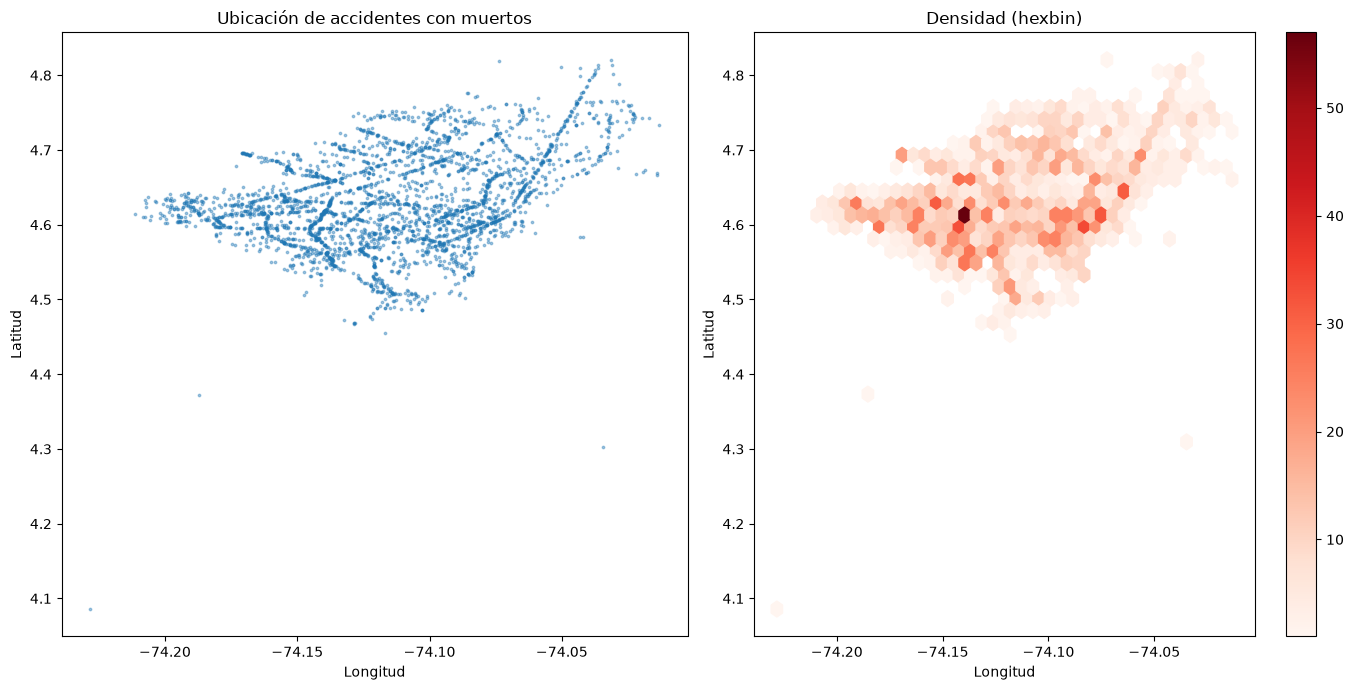

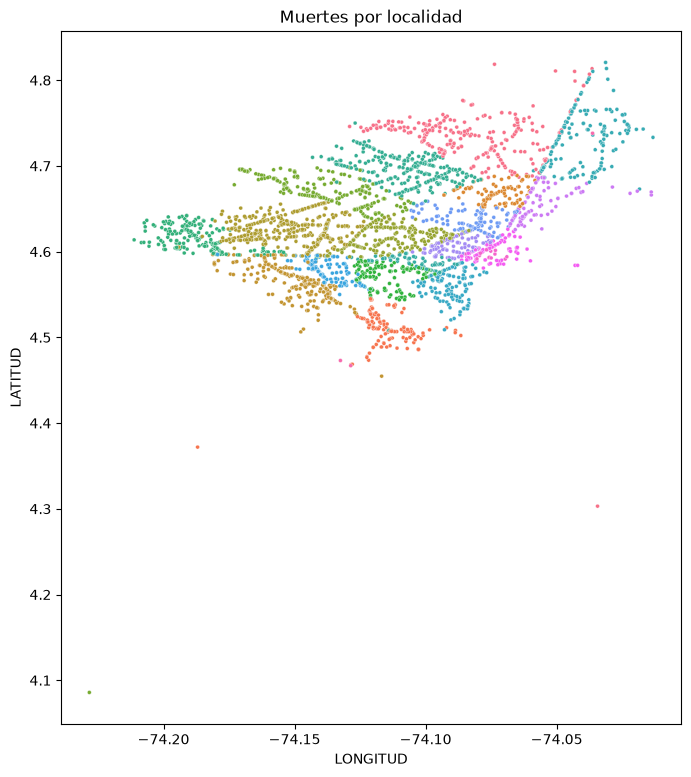

DIRECCION
AV AVENIDA BOYACA-AV AVENIDA PRIMERO DE MAYO 02    5
AV AVENIDA BOYACA-CL 44 S 02                       4
AV AVENIDA DE LAS AMERICAS-KR 68 02                4
AV AVENIDA BOYACA-CL 72 02                         3
CL 80-KR 72 2                                      3
AV AVENIDA CIUDAD DE CALI-CL 15A 91                3
KR 106-CL 15A 25                                   3
AK 68-CL 13 02                                     3
AC 80-KR 112 02                                    3
KR 80-CL 2 51                                      3
CL 6 - KR 47 02                                    2
AV AVENIDA DE LAS AMERICAS-KR 74 02                2
CL 61 S- KR 23 02                                  2
AV AVENIDA CIUDAD DE CALI-CL 11B 51                2
AV AVENIDA BOYACA-CL 72 2                          2
Name: count, dtype: int64
CIV
0.0           17
50008335.0     9
10003679.0     8
8005344.0      7
50008334.0     7
11012293.0     7
10000256.0     6
9003474.0      6
8000071.0      6
8008510.0   

In [14]:
# =========================================================
# 6. ANÁLISIS ESPACIAL
# =========================================================
# Coordenadas fuera del rango aproximado de Bogotá
fuera = dm[~dm["LATITUD"].between(3.7, 4.85) | ~dm["LONGITUD"].between(-74.45, -73.95)]
print("Registros con coordenadas sospechosas:", len(fuera))
dm = dm.drop(fuera.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].scatter(dm["LONGITUD"], dm["LATITUD"], s=3, alpha=0.4)
axes[0].set_title("Ubicación de accidentes con muertos")
hb = axes[1].hexbin(dm["LONGITUD"], dm["LATITUD"], gridsize=40, cmap="Reds", mincnt=1)
fig.colorbar(hb, ax=axes[1]); axes[1].set_title("Densidad (hexbin)")
for ax in axes: ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
plt.tight_layout(); plt.show()

# Coloreado por localidad
plt.figure(figsize=(8, 9))
sns.scatterplot(data=dm, x="LONGITUD", y="LATITUD", hue="LOCALIDAD", s=8, legend=False)
plt.title("Muertes por localidad"); plt.show()

# Direcciones / tramos (CIV) con más muertes
print(dm["DIRECCION"].value_counts().head(15))
print(dm["CIV"].value_counts().head(15))